<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_094_cnn_real_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 94/365 — Practical CNN on a Real Dataset

## Goal

Train a small **Convolutional Neural Network (CNN)** on a real handwritten-digit dataset.

Dataset:

**scikit-learn Digits**

- 1,797 real handwritten digit images
- each image is `8 × 8`
- 10 classes: `0` to `9`

This is a real dataset bundled with scikit-learn, so it works without downloading anything from the internet.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix


## 1. Load the real handwritten Digits dataset

In [2]:
digits = load_digits()

X = digits.images.astype(np.float32)
y = digits.target.astype(np.int64)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))


Images shape: (1797, 8, 8)
Labels shape: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]


The raw pixel values range from `0` to `16`.

Normalize them to `0–1`.


In [3]:
X = X / 16.0

print("Min pixel:", X.min())
print("Max pixel:", X.max())


Min pixel: 0.0
Max pixel: 1.0


## 2. Visualize real samples

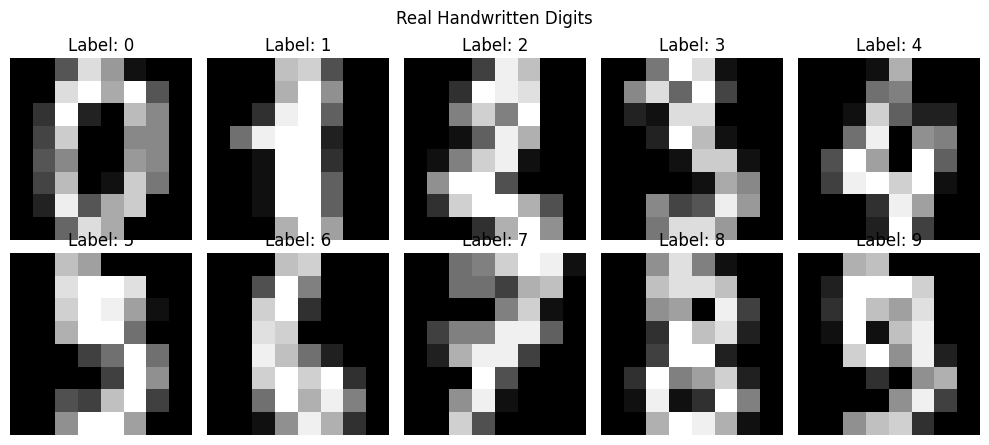

In [4]:
fig, axes = plt.subplots(2,5,figsize=(10,4.5))

for ax, image, label in zip(axes.ravel(), X[:10], y[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("Real Handwritten Digits")
plt.tight_layout()
plt.show()


## 3. Train/test split

Use a stratified split so every digit class remains represented.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (1437, 8, 8)
Test: (360, 8, 8)


## 4. Convert to PyTorch tensors

CNNs expect image tensors in the shape:

`[batch, channels, height, width]`

The digits are grayscale, so:

`channels = 1`


In [6]:
X_train_t = torch.tensor(
    X_train[:, None, :, :],
    dtype=torch.float32
)

X_test_t = torch.tensor(
    X_test[:, None, :, :],
    dtype=torch.float32
)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print(X_train_t.shape)


torch.Size([1437, 1, 8, 8])


## 5. Create mini-batches

In [7]:
train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    TensorDataset(X_test_t, y_test_t),
    batch_size=128,
    shuffle=False
)


## 6. Build a small CNN

Architecture:

`8×8 image`

→ Conv2D

→ ReLU

→ MaxPool

→ Conv2D

→ ReLU

→ MaxPool

→ Fully Connected Layer

→ 10 output logits


In [8]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


In [9]:
torch.manual_seed(42)

model = SmallCNN()

print(model)


SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


## 7. Loss and optimizer

This is multiclass classification.

Use:

- `CrossEntropyLoss`
- `Adam`


In [10]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


## 8. Train the CNN

In [11]:
history = {
    "train_loss": [],
    "test_acc": []
}

epochs = 15

for epoch in range(epochs):

    model.train()
    total_loss = 0
    total_samples = 0

    for xb, yb in train_loader:

        optimizer.zero_grad()

        logits = model(xb)

        loss = criterion(logits, yb)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * xb.size(0)
        total_samples += xb.size(0)

    train_loss = total_loss / total_samples

    model.eval()

    predictions = []
    actual = []

    with torch.no_grad():

        for xb, yb in test_loader:

            logits = model(xb)

            preds = logits.argmax(dim=1)

            predictions.extend(preds.numpy())
            actual.extend(yb.numpy())

    test_acc = accuracy_score(
        actual,
        predictions
    )

    history["train_loss"].append(train_loss)
    history["test_acc"].append(test_acc)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Test Accuracy: {test_acc:.4f}"
    )


Epoch 01 | Loss: 2.2906 | Test Accuracy: 0.1000
Epoch 02 | Loss: 2.2184 | Test Accuracy: 0.4722
Epoch 03 | Loss: 1.9791 | Test Accuracy: 0.6139
Epoch 04 | Loss: 1.4497 | Test Accuracy: 0.7444
Epoch 05 | Loss: 0.9570 | Test Accuracy: 0.8389
Epoch 06 | Loss: 0.6863 | Test Accuracy: 0.8611
Epoch 07 | Loss: 0.5397 | Test Accuracy: 0.8722
Epoch 08 | Loss: 0.4409 | Test Accuracy: 0.8944
Epoch 09 | Loss: 0.3751 | Test Accuracy: 0.9167
Epoch 10 | Loss: 0.3401 | Test Accuracy: 0.9333
Epoch 11 | Loss: 0.3046 | Test Accuracy: 0.9167
Epoch 12 | Loss: 0.2577 | Test Accuracy: 0.9278
Epoch 13 | Loss: 0.2532 | Test Accuracy: 0.9250
Epoch 14 | Loss: 0.2225 | Test Accuracy: 0.9306
Epoch 15 | Loss: 0.2067 | Test Accuracy: 0.9472


## 9. Plot training progress

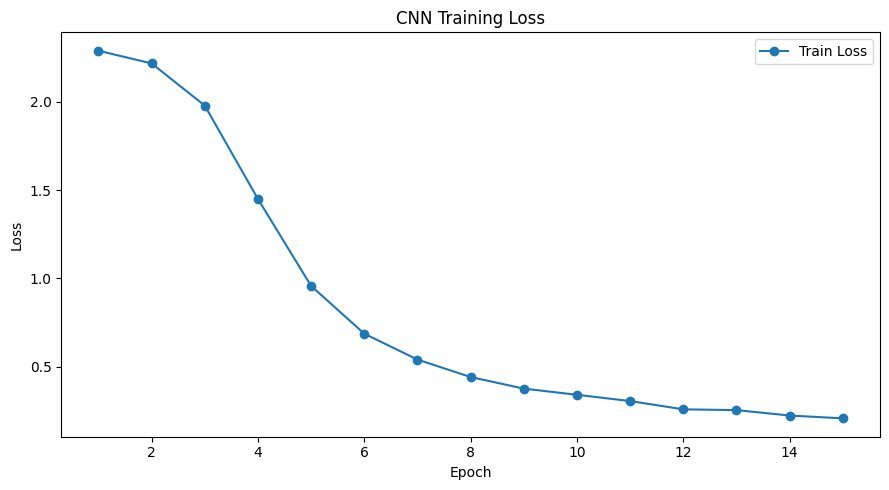

In [12]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, epochs+1),
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training Loss")
plt.legend()
plt.tight_layout()
plt.show()


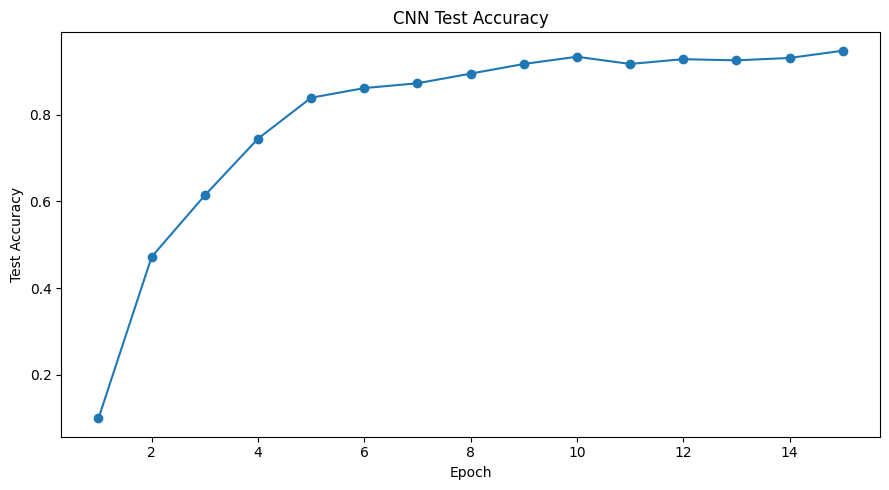

In [13]:
plt.figure(figsize=(9,5))

plt.plot(
    range(1, epochs+1),
    history["test_acc"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("CNN Test Accuracy")
plt.tight_layout()
plt.show()


## 10. Inspect real predictions

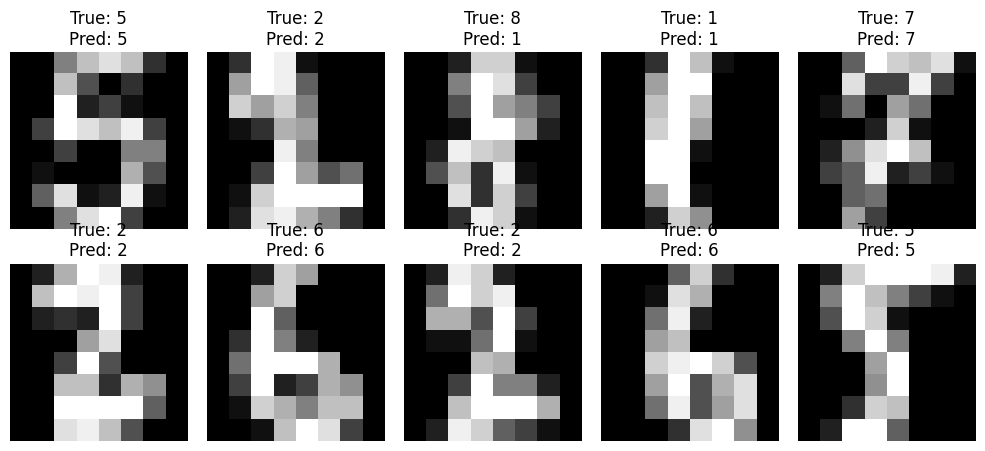

In [14]:
model.eval()

with torch.no_grad():
    logits = model(X_test_t[:10])
    preds = logits.argmax(dim=1).numpy()

fig, axes = plt.subplots(2,5,figsize=(10,4.5))

for ax, image, true_label, pred in zip(
    axes.ravel(),
    X_test[:10],
    y_test[:10],
    preds
):
    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {true_label}\nPred: {pred}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


## 11. Confusion matrix

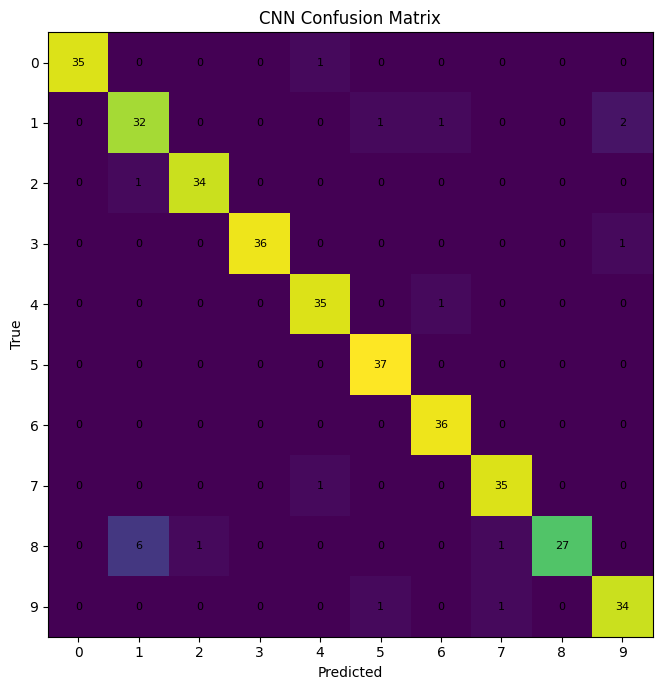

In [15]:
model.eval()

all_preds = []

with torch.no_grad():
    logits = model(X_test_t)
    all_preds = logits.argmax(dim=1).numpy()

cm = confusion_matrix(
    y_test,
    all_preds
)

plt.figure(figsize=(8,7))
plt.imshow(cm)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.xticks(range(10))
plt.yticks(range(10))

for i in range(10):
    for j in range(10):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()


## What did the CNN actually learn?

The convolution layers learn filters automatically.

Early filters may respond to local patterns such as:

- vertical strokes
- horizontal strokes
- curves
- corners

Deeper filters combine those smaller patterns into representations useful for distinguishing digits.

The model is not given handcrafted rules such as:

> “A 7 has this exact shape.”

It learns useful patterns from labeled examples.


## Why this implementation matters

This one notebook connects several concepts we already covered:

- Convolution
- Padding
- ReLU
- Max Pooling
- Mini-batches
- Cross-Entropy
- Adam
- Dropout
- Backpropagation

This is the point where the individual neural-network concepts start working together as a real system.


## Simple takeaway

A CNN learns filters from real image data.

Those filters detect useful local visual patterns, and deeper layers combine them to make the final classification.

> **Instead of manually defining image features, we let the CNN learn which visual patterns matter for the task.**


## References

- scikit-learn Digits dataset:
  https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html

- PyTorch Conv2d:
  https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html

- Stanford CS231n:
  https://cs231n.github.io/convolutional-networks/
